In [23]:
import warnings
warnings.filterwarnings("ignore")   # hide the warnings yfinance prints

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.linear_model import LinearRegression, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
import statsmodels.api as sm

Stock Dataset for each listed stock


In [2]:
# ---- Settings ----
TICKERS = ["AAPL", "MSFT", "JPM", "GS", "XOM", "JNJ", "UNH", "KO",
           "PG", "WMT", "AMZN", "HD", "CAT", "BA"]   # large companies across sectors
START = "2010-07-01"        # all tickers trade over the full period
END = "2022-12-31"          # train through 2022, test 2023 onward
DATA_END = "2026-11-07"
ANN = np.sqrt(252) * 100    # daily std -> annualized % (same units as VIX)


def normalize_dates(ticker):
    """Remove timezones and times so dates match across all tickers."""
    prices = yf.Ticker(ticker).history(start=START, end=DATA_END)["Close"]
    dates = pd.DatetimeIndex(pd.to_datetime(prices.index))
    if dates.tz is not None:
        dates = dates.tz_localize(None)
    prices.index = dates.normalize()
    return prices




def build_stock_data(ticker):
    """Predictors and target for one ticker. Each row is one trading day."""
    ret = normalize_dates(ticker).pct_change() # daily return

    df = pd.DataFrame(index=ret.index)
    df["vol_5d"] = ret.rolling(5).std() * ANN # week
    df["vol_21d"] = ret.rolling(21).std() * ANN # month
    df["vol_63d"] = ret.rolling(63).std() * ANN # quarter
    # Target volatility next 5 days
    df["fwd_vol"] = ret.rolling(5).std().shift(-5) * ANN
    return df.dropna()


c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
c:\User

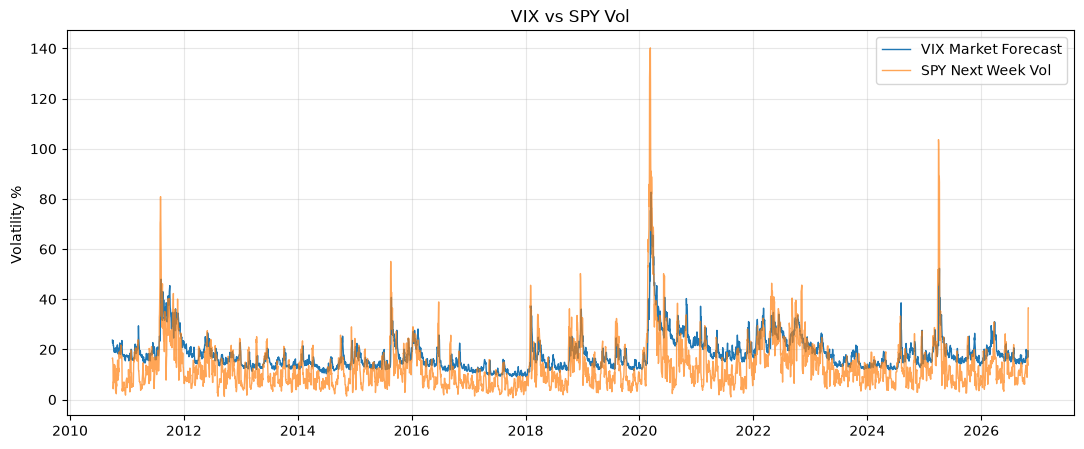

In [3]:
# Spy and VIX
vix = normalize_dates("^VIX") # market forecast volatility
spy_df = build_stock_data("SPY")
spy_df["vix"] = vix # add VIX to spy data
spy_df = spy_df.dropna()

# Plot 1 Vix vs. Actual Spy volatility next week

plt.figure(figsize=(13,5))
plt.plot(spy_df.index, spy_df["vix"], lw=1, label="VIX Market Forecast")
plt.plot(spy_df.index, spy_df["fwd_vol"], lw=1, alpha = 0.7, label="SPY Next Week Vol")
plt.ylabel("Volatility % ")
plt.title("VIX vs SPY Vol")
plt.legend()
plt.grid(alpha = 0.3)
plt.show()


Which Predictor Best Lines up with the Target

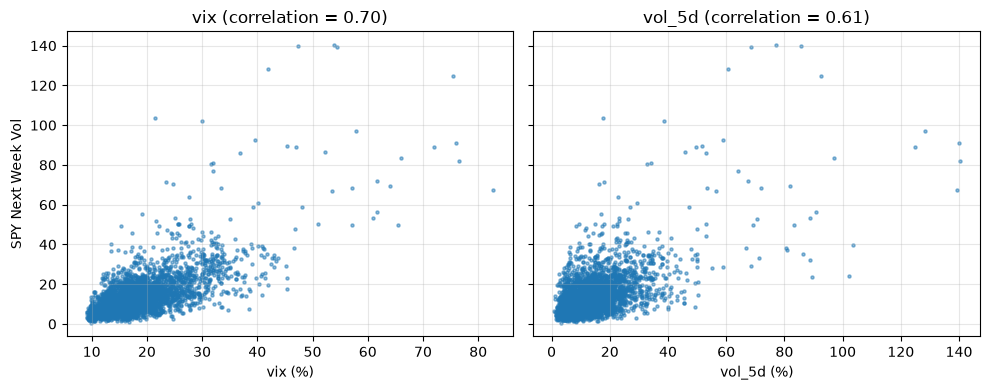

In [4]:
fig, axes = plt.subplots(1,2, figsize=(10,4), sharey=True)
for ax, col in zip(axes, ["vix", "vol_5d"]):
    r = spy_df[col].corr(spy_df["fwd_vol"])
    ax.scatter(spy_df[col], spy_df["fwd_vol"], s=5, alpha=0.5)
    ax.set_title(f"{col} (correlation = {r:.2f})")
    ax.set_xlabel(f"{col} (%)")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("SPY Next Week Vol")
plt.tight_layout()
plt.show()

Data for 14 Stocks

In [5]:
stock_data = {}
for t in TICKERS:
    stock_data[t] = build_stock_data(t)
    print(f"{t}: {len(stock_data[t])} rows")

c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

AAPL: 4046 rows


c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

MSFT: 4046 rows


c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

JPM: 4046 rows


... (17 outputs left out)

HD: 4046 rows


c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

CAT: 4046 rows
BA: 4046 rows


c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

Combined data for stocks

In [6]:
combined = pd.DataFrame(index=spy_df.index)

# Spy's volatility (baseline) and Vix (benchmark)
combined["spy_vol_5d"] = spy_df["vol_5d"]
combined["spy_vol_21d"] = spy_df["vol_21d"]
combined["spy_vol_63d"] = spy_df["vol_63d"]
combined["vix"] = spy_df["vix"]

#  Past volatility for each stock
for t in TICKERS:
    for w in ["5d", "21d", "63d"]:
        combined[f"{t}_vol_{w}"] = stock_data[t][f"vol_{w}"]
combined["target"] = spy_df["fwd_vol"]
combined = combined.dropna()
print(combined.shape)

(4046, 47)


Train and Test Split

In [7]:
train = combined.loc[combined.index <= END] # 2010-2022
test = combined.loc[combined.index > END]   # 2023 +

#Dropping last 5 training dayys: targets use 2023 prices which isn't in the test period
train = train.iloc[:-5]

X_train = train.drop(columns=["target"])
y_train = train["target"]
X_test = test.drop(columns=["target"])
y_test = test["target"]


#Column groups used by the models
BASELINE_COLS = ["spy_vol_5d", "spy_vol_21d", "spy_vol_63d"]
STOCK_COLS = [f"{t}_vol_{w}" for t in TICKERS for w in ["5d", "21d", "63d"]]
ALL_COLS = BASELINE_COLS + STOCK_COLS # 45 predictors

print(f"Training rows: {len(train)} ({train.index[0].date()} to {train.index[-1].date()})")
print(f"Test rows: {len(test)} ({test.index[0].date()} to {test.index[-1].date()})")

Training rows: 3080 (2010-09-30 to 2022-12-22)
Test rows: 961 (2023-01-03 to 2026-10-30)


Summary of target

In [8]:
# Volatile week: top 25% of training weeks
threshold = y_train.quantile(0.75)
spy_volatile = (combined["target"] > threshold).astype(int) # classification 
target_summary = pd.DataFrame({
    "mean %": [y_train.mean(), y_test.mean()],
    "median %": [y_train.median(), y_test.median()],
    "skew": [y_train.skew(), y_test.skew()],
    "volatile weeks %": [spy_volatile[train.index].mean() * 100,
                         spy_volatile[test.index].mean() * 100],
}, index=["Train (2010-2022)", "Test (2023+)"]).round(2)

print(f"Volatile-week threshold: {threshold:.2f}%")
target_summary

Volatile-week threshold: 17.24%


,mean %,median %,skew,volatile weeks %
Train (2010-2022),13.79,10.95,3.86,25.00
Test (2023+),12.64,11.33,5.39,17.59


Which Stocks past weeks tracks SPY's volatility

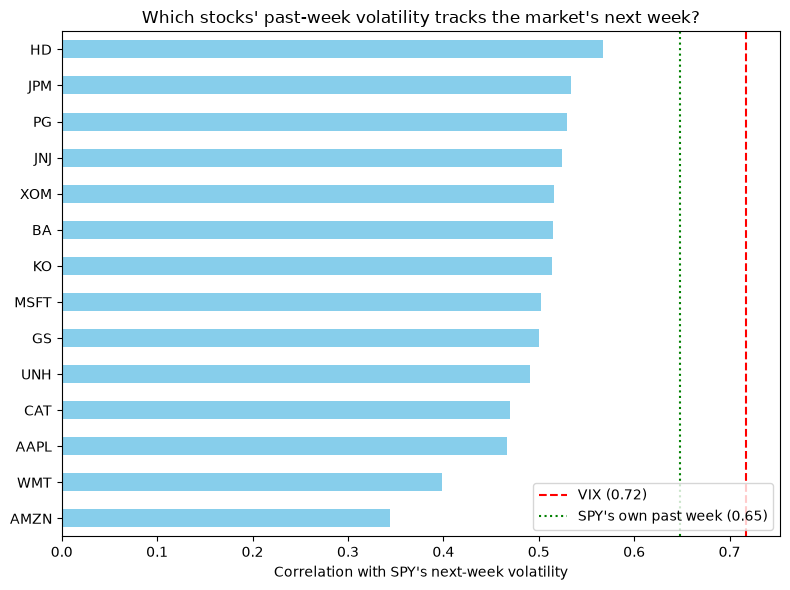

In [9]:
# Uses Training Data Only test period is unseen
stock_corr = pd.Series(
    {t: train[f"{t}_vol_5d"].corr(y_train) for t in TICKERS}).sort_values()
vix_corr = train["vix"].corr(y_train)
spy_corr = train["spy_vol_5d"].corr(y_train)

stock_corr.plot(kind="barh", figsize=(8, 6), color="skyblue")
plt.axvline(vix_corr, color="red", ls="--", label=f"VIX ({vix_corr:.2f})")
plt.axvline(spy_corr, color="green", ls=":", label=f"SPY's own past week ({spy_corr:.2f})")
plt.xlabel("Correlation with SPY's next-week volatility")
plt.title("Which stocks' past-week volatility tracks the market's next week?")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


How Correlated ae the stocks with each other

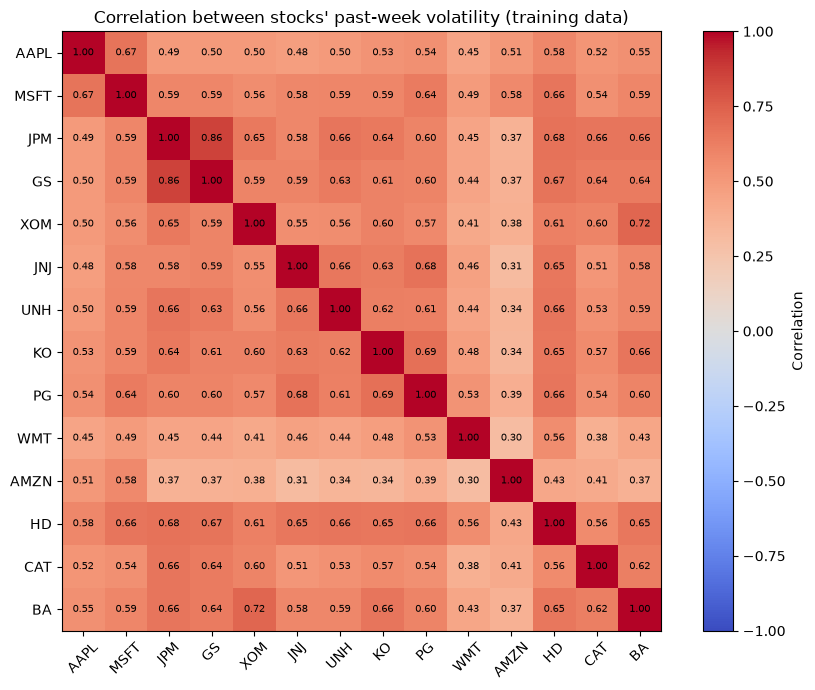

In [10]:
corr_matrix = train[[f"{t}_vol_5d" for t in TICKERS]].corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(TICKERS)), TICKERS, rotation=45)
plt.yticks(range(len(TICKERS)), TICKERS)

# Write the value in each square
for i in range(len(TICKERS)):
    for j in range(len(TICKERS)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)

plt.title("Correlation between stocks' past-week volatility (training data)")
plt.tight_layout()
plt.show()

Helper Functions and Linear Regression: We fit a linear regression model on the training data using columns and return the test MSE,R^2, and fitted model       


In [11]:
def fit_and_score(cols):
    """Fitting linear regresion on training data using cols. Returns test MSE, test R2 and model."""
    model = LinearRegression().fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    scores =  {"test_MSE": mean_squared_error(y_test, pred),
            "test_R2": r2_score(y_test, pred)
            }
    return scores, model

def pct_reduct(mse): 
    """Percent reduction vs baseline. Positive is better than baseline"""
    base = baseline_scores["test_MSE"]
    return (base - mse)/base*100

Benchmark and Baseline for VIX

In [12]:
# Naive guess, no fitting: next week's volatility = last week's
naive_scores = {"test_MSE": mean_squared_error(y_test, X_test["spy_vol_5d"]),
                "test_R2": r2_score(y_test, X_test["spy_vol_5d"])}

baseline_scores, baseline_model = fit_and_score(BASELINE_COLS)
vix_scores, vix_model = fit_and_score(BASELINE_COLS + ["vix"])

benchmark_table = pd.DataFrame({
    "Naive (next week = last week)": naive_scores,
    "Baseline (SPY past vol)": baseline_scores,
    "VIX benchmark (SPY past vol + VIX)": vix_scores,
}).T.round(3)
benchmark_table

,test_MSE,test_R2
Naive (next week = last week),84.804,-0.202
Baseline (SPY past vol),62.466,0.115
VIX benchmark (SPY past vol + VIX),48.868,0.308


One Stock at a Time

      test_MSE  test_R2  MSE_reduction_%
JNJ     59.006    0.164            5.539
KO      61.859    0.123            0.972
PG      61.911    0.123            0.888
XOM     61.990    0.122            0.762
MSFT    62.505    0.114           -0.063
AMZN    62.642    0.112           -0.281
BA      62.965    0.108           -0.799
WMT     62.977    0.108           -0.818
AAPL    63.108    0.106           -1.029
CAT     63.183    0.105           -1.148
JPM     63.320    0.103           -1.368
GS      64.083    0.092           -2.589
HD      64.634    0.084           -3.471
UNH     65.174    0.076           -4.336


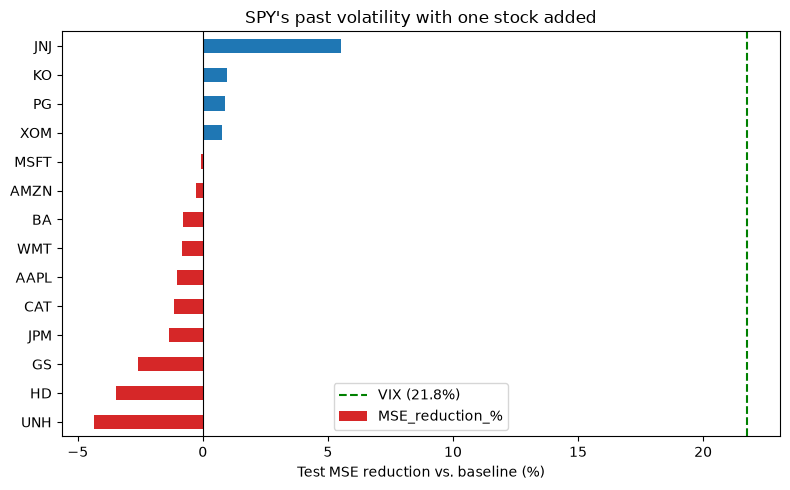

In [13]:
rows = []
for t in TICKERS:
    # Baseline + this one stock's past week, month, and quarter
    cols = BASELINE_COLS + [f"{t}_vol_5d", f"{t}_vol_21d", f"{t}_vol_63d"]
    scores, _ = fit_and_score(cols)
    scores["MSE_reduction_%"] = pct_reduct(scores["test_MSE"])
    rows.append(pd.Series(scores, name=t))

stock_rank = pd.DataFrame(rows).sort_values("MSE_reduction_%").round(3)
print(stock_rank.iloc[::-1])             # best stock first

vix_reduction = pct_reduct(vix_scores["test_MSE"])

colors = ["tab:blue" if v > 0 else "tab:red" for v in stock_rank["MSE_reduction_%"]]
stock_rank["MSE_reduction_%"].plot(kind="barh", figsize=(8, 5), color=colors)
plt.axvline(vix_reduction, color="green", ls="--", label=f"VIX ({vix_reduction:.1f}%)")
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Test MSE reduction vs. baseline (%)")
plt.title("SPY's past volatility with one stock added")
plt.legend()
plt.tight_layout()
plt.show()

LASSO with a regression on all 14 stocks

In [14]:
allstock_scores, allstock_model = fit_and_score(ALL_COLS)
train_R2 = allstock_model.score(X_train[ALL_COLS], y_train)   # .score gives R^2

# A big gap between training and test R^2 is a sign of overfitting
print(f"Train R^2 = {train_R2:.3f}, test R^2 = {allstock_scores['test_R2']:.3f}")
print(f"Test MSE reduction vs. baseline: {pct_reduct(allstock_scores['test_MSE']):.1f}%")

# Correlated predictors give unstable coefficients, e.g., the two banks
coefs = pd.Series(allstock_model.coef_, index=ALL_COLS)
print("\nJPM and GS coefficients:")
print(coefs.filter(regex="^(JPM|GS)_").round(3))

Train R^2 = 0.486, test R^2 = -0.137
Test MSE reduction vs. baseline: -28.4%

JPM and GS coefficients:
JPM_vol_5d     0.009
JPM_vol_21d    0.069
JPM_vol_63d   -0.182
GS_vol_5d     -0.028
GS_vol_21d    -0.093
GS_vol_63d    -0.035
dtype: float64


LASSO and choosing lambda with cross validation 
We standardize the columns in `cols` (scaler fit on training data only),
pick lambda by cross-validation, then refit lasso on all training data.
Return the fitted model, the scaler, the best lambda, and the CV MSE for each lambda

Best lambda: 0.2314
Lasso test MSE = 59.67, R^2 = 0.154, reduction vs. baseline = 4.5%


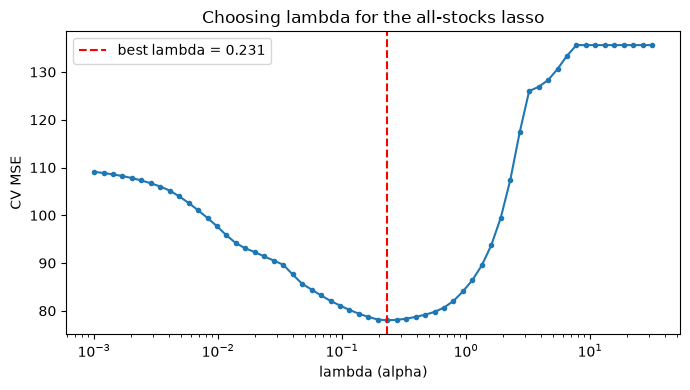

In [15]:
# TimeSeriesSplit is K-fold CV for time series: each fold trains on the past
# and validates on the future. gap=5 skips the 5 days whose targets overlap.
tscv = TimeSeriesSplit(n_splits=5, gap=5)
ALPHAS = np.logspace(-3, 1.5, 60)     # lambda values to try (sklearn calls it alpha)


def lasso_cv(cols):
    """Standardizing columns and pick lambda with TimeSeriesSplit. Then refit the lasso on all training data"""
    scaler = StandardScaler().fit(X_train[cols])
    Xtr = scaler.transform(X_train[cols])

    cv_mse = []
    for a in ALPHAS:
        mse = -cross_val_score(Lasso(alpha=a, max_iter=100_000), Xtr, y_train,
                               cv=tscv, scoring="neg_mean_squared_error")
        cv_mse.append(mse.mean())

    best_alpha = ALPHAS[np.argmin(cv_mse)]
    model = Lasso(alpha=best_alpha, max_iter=100_000).fit(Xtr, y_train)
    return model, scaler, best_alpha, cv_mse


def lasso_test_scores(model, scaler, cols):
    """Test MSE and R2 for given model and columns"""
    
    pred = model.predict(scaler.transform(X_test[cols]))
    return {"test_MSE": mean_squared_error(y_test, pred),
            "test_R2": r2_score(y_test, pred)}


lasso_model, lasso_scaler, best_alpha, cv_mse = lasso_cv(ALL_COLS)
lasso_scores = lasso_test_scores(lasso_model, lasso_scaler, ALL_COLS)

print(f"Best lambda: {best_alpha:.4f}")
print(f"Lasso test MSE = {lasso_scores['test_MSE']:.2f}, R^2 = {lasso_scores['test_R2']:.3f}, "
      f"reduction vs. baseline = {pct_reduct(lasso_scores['test_MSE']):.1f}%")

# CV error for each lambda, showing how the best one was chosen
plt.figure(figsize=(7, 4))
plt.semilogx(ALPHAS, cv_mse, marker=".")
plt.axvline(best_alpha, color="red", ls="--", label=f"best lambda = {best_alpha:.3g}")
plt.xlabel("lambda (alpha)")
plt.ylabel("CV MSE")
plt.title("Choosing lambda for the all-stocks lasso")
plt.legend()
plt.tight_layout()
plt.show()

What Stocks Does LASSO Pick?

Lasso kept 14 of 45 predictors:
spy_vol_5d      3.426
spy_vol_21d     1.163
PG_vol_5d       0.807
JNJ_vol_5d      0.728
HD_vol_5d       0.497
spy_vol_63d     0.433
XOM_vol_5d      0.389
AMZN_vol_63d    0.365
UNH_vol_21d     0.333
AAPL_vol_21d    0.316
AAPL_vol_5d     0.139
WMT_vol_5d      0.055
JNJ_vol_63d    -0.026
XOM_vol_21d     0.007
dtype: float64

Kept stocks: ['AAPL', 'XOM', 'JNJ', 'UNH', 'PG', 'WMT', 'AMZN', 'HD']
At most one of JPM/GS kept: True
JNJ kept: True


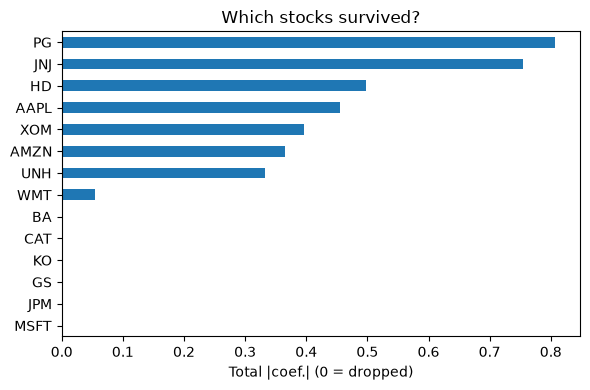

In [16]:
lasso_coefs = pd.Series(lasso_model.coef_, index=ALL_COLS)
keep = lasso_coefs[lasso_coefs!=0]
print(f"Lasso kept {len(keep)} of {len(ALL_COLS)} predictors:")
print(keep.sort_values(key=abs, ascending=False).round(3))

# One number for each stock: total coefficient over the 5,21,63 day indows
by_stock = pd.Series(
    {t: lasso_coefs.filter(regex=f"^{t}_").abs().sum() for t in TICKERS}
)
keep_stocks = by_stock[by_stock > 0].index.tolist()
print("\nKept stocks:", keep_stocks)

# Prediction check 
print("At most one of JPM/GS kept:", ("JPM" in keep_stocks) + ("GS" in keep_stocks) <= 1)
print("JNJ kept:", "JNJ" in keep_stocks)


by_stock.sort_values().plot(
    kind = "barh", figsize=(6,4),
    color=["tab:blue" if v > 0 else "tab:red" for v in by_stock.sort_values()])
plt.xlabel("Total |coef.| (0 = dropped)")
plt.title("Which stocks survived?")
plt.tight_layout()
plt.show()

Is Lasso stable over time?

In [17]:

# We refit lasso on each CV fold to check which stocks are kept
times_kept = pd.Series(0, index=TICKERS)

for k, (tr_idx, _) in enumerate(tscv.split(X_train), start=1):
    scaler = StandardScaler().fit(X_train[ALL_COLS].iloc[tr_idx])
    Xtr = scaler.transform(X_train[ALL_COLS].iloc[tr_idx])
    m = Lasso(alpha=best_alpha, max_iter=100_000).fit(Xtr, y_train.iloc[tr_idx])

    c = pd.Series(m.coef_, index=ALL_COLS)
    kept_here = [t for t in TICKERS if (c.filter(regex=f"^{t}_") != 0).any()]
    times_kept[kept_here] += 1
    print(f"Fold {k} (trained through {X_train.index[tr_idx[-1]].date()}): {kept_here}")

print(f"\nTimes each stock was kept (out of {tscv.n_splits} folds):")
print(times_kept.sort_values(ascending=False))

Fold 1 (trained through 2012-10-05): ['AAPL', 'MSFT', 'JPM', 'GS', 'XOM', 'JNJ', 'UNH', 'KO', 'PG', 'HD', 'CAT', 'BA']
Fold 2 (trained through 2014-10-22): ['AAPL', 'MSFT', 'JPM', 'GS', 'XOM', 'JNJ', 'UNH', 'KO', 'PG', 'HD', 'CAT']
Fold 3 (trained through 2016-11-03): ['AAPL', 'MSFT', 'XOM', 'JNJ', 'UNH', 'PG', 'AMZN', 'CAT', 'BA']
Fold 4 (trained through 2018-11-16): ['AAPL', 'MSFT', 'XOM', 'JNJ', 'UNH', 'AMZN', 'CAT', 'BA']
Fold 5 (trained through 2020-12-02): ['AAPL', 'XOM', 'JNJ', 'UNH', 'PG', 'WMT', 'AMZN', 'HD', 'CAT']

Times each stock was kept (out of 5 folds):
AAPL    5
JNJ     5
XOM     5
UNH     5
CAT     5
MSFT    4
PG      4
BA      3
HD      3
AMZN    3
JPM     2
GS      2
KO      2
WMT     1
dtype: int64


Model with every column, stock, and vix included

In [18]:
EVERYTHING_COLS = ALL_COLS + ["vix"]
every_model, every_scaler, every_alpha, _ = lasso_cv(EVERYTHING_COLS)
every_scores = lasso_test_scores(every_model, every_scaler, EVERYTHING_COLS)
every_coefs = pd.Series(every_model.coef_, index=EVERYTHING_COLS)

print(f"Best Lambda: {every_alpha:.4f}")
print(f"Test MSE = {every_scores['test_MSE']:.2f}, "
    f"R2 = {every_scores['test_R2']:.3f}, "
    f"reduction vs baseline = {pct_reduct(every_scores['test_MSE']):.1f}%")
print(f"VIX coefficient: {every_coefs['vix']:.3f}")
print("Stocks still kept alongside VIX:",
      [t for t in TICKERS if (every_coefs.filter(regex=f"^{t}_") != 0).any()])

Best Lambda: 0.1366
Test MSE = 48.95, R2 = 0.306, reduction vs baseline = 21.6%
VIX coefficient: 8.127
Stocks still kept alongside VIX: ['AAPL', 'JPM', 'GS', 'XOM', 'JNJ', 'UNH', 'PG', 'WMT', 'HD', 'BA']


Comparison of the regression models

                                   test_MSE  test_R2  MSE_reduction_percentage
Naive (next week = last week)        84.804   -0.202                   -35.761
Baseline (SPY past vol)              62.466    0.115                     0.000
Best single stock                    59.006    0.164                     5.539
All stocks with linear regression    80.228   -0.137                   -28.434
All stocks with LASSO                59.671    0.154                     4.474
VIX benchmark                        48.868    0.308                    21.768
All stocks + VIX, LASSO              48.950    0.306                    21.637


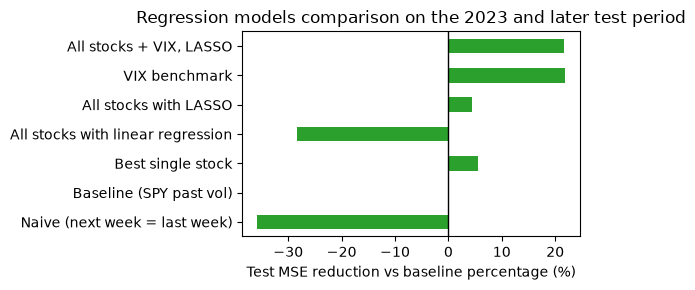

In [23]:
comp_table = pd.DataFrame({
    "Naive (next week = last week)": naive_scores,
    "Baseline (SPY past vol)": baseline_scores,
    "Best single stock": fit_and_score(BASELINE_COLS + ["JNJ_vol_5d", "JNJ_vol_21d", "JNJ_vol_63d"])[0],
    "All stocks with linear regression": allstock_scores,
    "All stocks with LASSO": lasso_scores,
    "VIX benchmark": vix_scores,
    "All stocks + VIX, LASSO": every_scores,
}).T
comp_table["MSE_reduction_percentage"] = pct_reduct(comp_table["test_MSE"])
comp_table = comp_table.round(3)
print(comp_table)

comp_table["MSE_reduction_percentage"].plot(kind="barh", figsize=(6,3), color="tab:green")
plt.axvline(0, color="black", lw=1)
plt.xlabel("Test MSE reduction vs baseline percentage (%)")
plt.title("Regression models comparison on the 2023 and later test period")
plt.tight_layout()
plt.show()


## Results

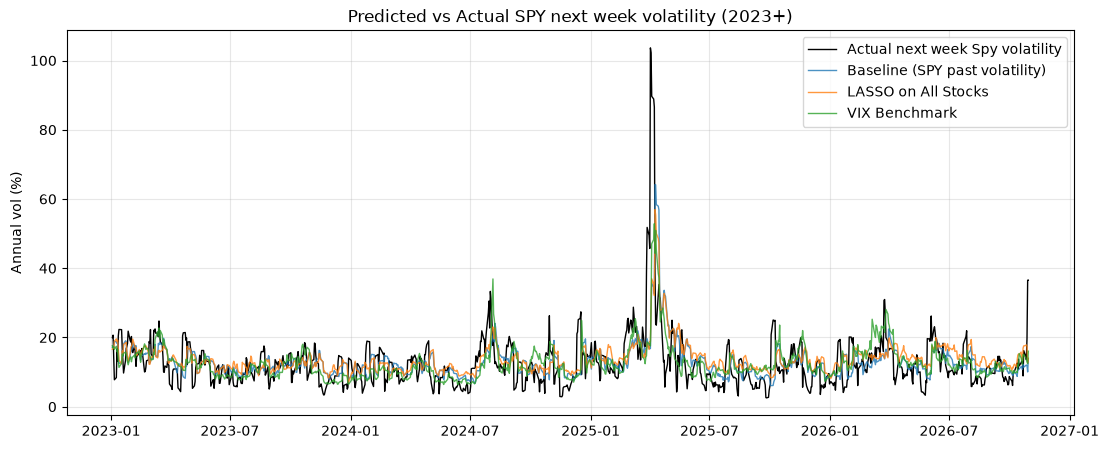

In [27]:
# Running predictions for the test period (2023 +) from the trained models

preds = pd.DataFrame({
    "Actual": y_test,
    "Baseline (SPY past volatility)": baseline_model.predict(X_test[BASELINE_COLS]),
    "LASSO on All Stocks": lasso_model.predict(lasso_scaler.transform(X_test[ALL_COLS])),
    "VIX Benchmark": vix_model.predict(X_test[BASELINE_COLS + ["vix"]]),
    
}, index=y_test.index)

#Predicted vs actual plot
fig, ax = plt.subplots(figsize=(13,5))
ax.plot(preds.index, preds["Actual"], lw=1, color="black", label="Actual next week Spy volatility")
for col in ["Baseline (SPY past volatility)", "LASSO on All Stocks", "VIX Benchmark"]:
    ax.plot(preds.index, preds[col], lw=1, alpha=0.8, label=col)
ax.set_ylabel("Annual vol (%)")
ax.set_title("Predicted vs Actual SPY next week volatility (2023+)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# April 2025 Spike

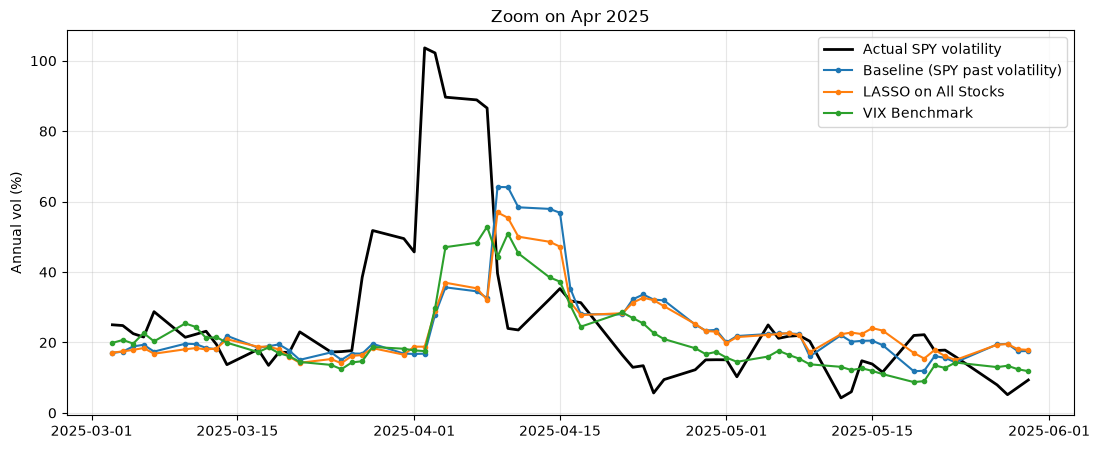

Peak day: 2025-04-02
Actual                            103.6
Baseline (SPY past volatility)     16.8
LASSO on All Stocks                18.8
VIX Benchmark                      17.6
Name: 2025-04-02 00:00:00, dtype: float64


In [28]:
# focusing in on between March and May 2025
spike = preds.loc["2025-03":"2025-05"]
fig, ax = plt.subplots(figsize=(13,5))
ax.plot(spike.index, spike["Actual"], lw=2, color="black", label="Actual SPY volatility")
for col in ["Baseline (SPY past volatility)", "LASSO on All Stocks", "VIX Benchmark"]:
    ax.plot(spike.index, spike[col], lw=1.5, marker=("."), label=col)
ax.set_ylabel("Annual vol (%)")
ax.set_title("Zoom on Apr 2025")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# What each model predicted on the worst day
peak_day = spike["Actual"].idxmax()
print(f"Peak day: {peak_day.date()}")
print(spike.loc[peak_day].round(1))

# Which stocks were the best indicators?


In [30]:
# Using stocks that were kept when VIX is in the model
vix_kept = [t for t in TICKERS if (every_coefs.filter(regex=f"^{t}_") != 0).any()]

#One row per stock
indicator_table = pd.DataFrame({
    "alone_MSE_reduction_%": stock_rank["MSE_reduction_%"],
    "kept_by_lasso": [t in keep_stocks for t in stock_rank.index],
    "folds_kept_(of_5)": times_kept[stock_rank.index],
    "kept_with_VIX": [t in vix_kept for t in stock_rank.index],
}).sort_values("alone_MSE_reduction_%", ascending=False)
print(indicator_table)


      alone_MSE_reduction_%  kept_by_lasso  folds_kept_(of_5)  kept_with_VIX
JNJ                   5.539           True                  5           True
KO                    0.972          False                  2          False
PG                    0.888           True                  4           True
XOM                   0.762           True                  5           True
MSFT                 -0.063          False                  4          False
AMZN                 -0.281           True                  3          False
BA                   -0.799          False                  3           True
WMT                  -0.818           True                  1           True
AAPL                 -1.029           True                  5           True
CAT                  -1.148          False                  5          False
JPM                  -1.368          False                  2           True
GS                   -2.589          False                  2           True

# CI for JNJ


In [31]:
# Additional improvement: 
# Using same model as the "best single stock", fit with statsmodes to get p-values and CI
jnj_cols = BASELINE_COLS + ["JNJ_vol_5d", "JNJ_vol_21d", "JNJ_vol_63d"]
X_jnj = sm.add_constant(X_train[jnj_cols])
ols = sm.OLS(y_train, X_jnj).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.456
Model:                            OLS   Adj. R-squared:                  0.454
Method:                 Least Squares   F-statistic:                     428.5
Date:                Sat, 21 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:34:09   Log-Likelihood:                -10893.
No. Observations:                3080   AIC:                         2.180e+04
Df Residuals:                    3073   BIC:                         2.184e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           3.5501      0.391      9.085      

In [38]:
print(strategies.columns)

Index(['Buy and hold SPY', 'Base', 'LASSO', 'VIX Benchmark'], dtype='str')


# Volatility targeting strategy

In [41]:
# Hold less SPY when a model predicts high volatility or more when it is low

# SPY's daily % change for test period
spy_ret = normalize_dates("SPY").pct_change()
spy_ret = spy_ret.loc[preds.index]

# Target volatility average next week volatility with training data
target_vol = y_train.mean()

# How much our money is in SPY each day (1 = 100%)
base_position = np.minimum(target_vol / preds["Baseline (SPY past volatility)"], 1)
lasso_position = np.minimum(target_vol / preds["LASSO on All Stocks"], 1)
vix_position = np.minimum(target_vol / preds["VIX Benchmark"], 1)

# Daily return of each strategy
strategies = pd.DataFrame(index=preds.index)
strategies["Buy and hold SPY"] = spy_ret
strategies["Baseline sizing"] = base_position.shift(1) * spy_ret
strategies["LASSO sizing"] = lasso_position.shift(1) * spy_ret
strategies["VIX sizing"] = vix_position.shift(1) * spy_ret
strategies = strategies.dropna()

Target Volatility: 13.79%
                  total_return_%  annual_vol_%  max_drawdown_%
Buy and hold SPY          108.05         14.86          -18.76
Baseline sizing            92.76         12.61          -13.86
LASSO sizing               92.49         12.46          -13.50
VIX sizing                 87.88         12.24          -13.61


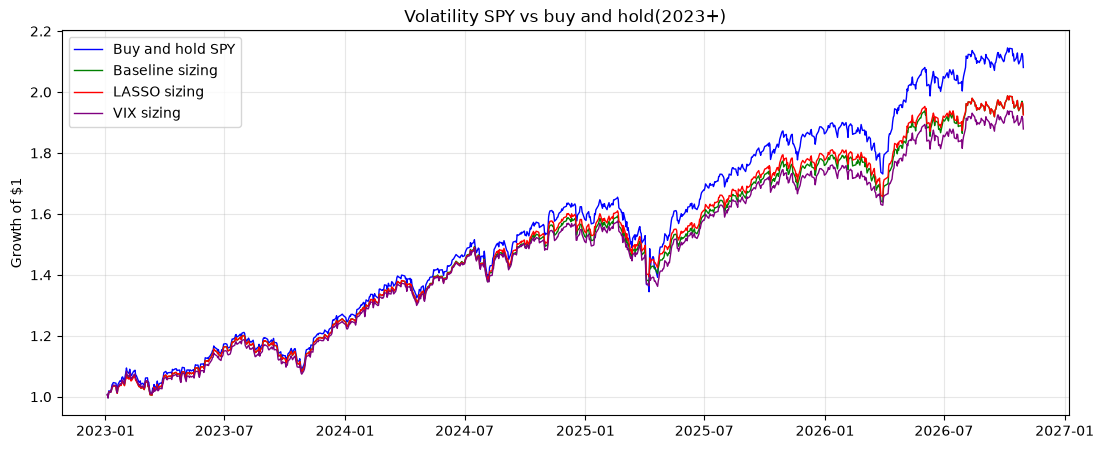

In [42]:
# Compare strategy returns and plot
# growth of $1 for each strategy

growth = (1 + strategies).cumprod()
drawdown = growth / growth.cummax() - 1

strategy_table = pd.DataFrame({
    "total_return_%": (growth.iloc[-1] - 1) * 100,
    "annual_vol_%": strategies.std() * ANN,
    "max_drawdown_%": drawdown.min() * 100,
}).round(2)
print(f"Target Volatility: {target_vol:.2f}%")
print(strategy_table)

# Plot growth of $1
fig, ax = plt.subplots(figsize=(13,5))
ax.plot(growth.index, growth["Buy and hold SPY"], lw = 1, color='blue', label = "Buy and hold SPY")
ax.plot(growth.index, growth["Baseline sizing"], lw = 1, color='green', label = "Baseline sizing")
ax.plot(growth.index, growth["LASSO sizing"], lw = 1, color='red', label = "LASSO sizing")
ax.plot(growth.index, growth["VIX sizing"], lw = 1, color='purple', label = "VIX sizing")
ax.set_ylabel("Growth of $1")
ax.set_title("Volatility SPY vs buy and hold(2023+)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()